In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/CooperUnion/anime-recommendations-database/anime.csv
/kaggle/input/datasets/CooperUnion/anime-recommendations-database/rating.csv
/kaggle/input/models/qwen-lm/qwen-3/transformers/0.6b-base/1/config.json
/kaggle/input/models/qwen-lm/qwen-3/transformers/0.6b-base/1/merges.txt
/kaggle/input/models/qwen-lm/qwen-3/transformers/0.6b-base/1/README.md
/kaggle/input/models/qwen-lm/qwen-3/transformers/0.6b-base/1/tokenizer.json
/kaggle/input/models/qwen-lm/qwen-3/transformers/0.6b-base/1/vocab.json
/kaggle/input/models/qwen-lm/qwen-3/transformers/0.6b-base/1/tokenizer_config.json
/kaggle/input/models/qwen-lm/qwen-3/transformers/0.6b-base/1/model.safetensors
/kaggle/input/models/qwen-lm/qwen-3/transformers/0.6b-base/1/generation_config.json


# Anime Adventure Blog: How I Built a Smart Recommendation Bot


## Model - Qwen3
Qwen3 is a large language model (LLM) developed by Alibaba Cloud, part of the Qwen series — one of the most powerful open-source LLMs available today. It's trained on massive amounts of text data from the web, books, code, and more.

##  Key Features of Qwen3:
| Feature                     | Description                                                                     |
|-----------------------------|---------------------------------------------------------------------------------|
| Multilingual Support        | Understands and generates text in multiple languages including English, Chinese, Japanese, Korean, etc. |
| Code Writing & Explanation  | Write scripts, debug, or explain programming logic.                             |
| Dialogue Understanding      | Built to understand and generate conversationally natural responses.            |
| Creative Writing            | Generate stories, poems, screenplays, and fictional worlds.                     |
| Reasoning & Logic           | Solve puzzles, math problems, and logical questions.                             |
| Fine-tuned for Tasks        | Some versions are fine-tuned for specific domains like storytelling, coding, and chatbots. |


## Task Outline: What This Notebook Does

The notebook you're building leverages Qwen3’s capabilities in combination with a real anime recommendation dataset, allowing users to:

- Understand Anime Trends
- Generate Personalized Anime Recommendations
- Combine Data Filtering with AI Creativity
- Anime Recommendation depends on out mood using Qwen Thinking mode.

## 1. Setup & Dependencies

In [2]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch


## 2. Load Qwen3 Model and Tokenizer


In [3]:
import os
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM

# 1. Correct model path based on Kaggle input directory
model_path = "/kaggle/input/models/qwen-lm/qwen-3/transformers/0.6b-base/1"
print("Files in model path:", os.listdir(model_path))

# 2. Load tokenizer and model locally
tokenizer = AutoTokenizer.from_pretrained(model_path, local_files_only=True, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    model_path, 
    local_files_only=True, 
    trust_remote_code=True,
    torch_dtype=torch.float16
).to("cuda" if torch.cuda.is_available() else "cpu")

# 3. Load dataset with correct path
dataset_path = "/kaggle/input/datasets/CooperUnion/anime-recommendations-database/anime.csv"
df = pd.read_csv(dataset_path)
print(df.head(5))

Files in model path: ['config.json', 'merges.txt', 'README.md', 'tokenizer.json', 'vocab.json', 'tokenizer_config.json', 'model.safetensors', 'generation_config.json']


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

   anime_id                              name  \
0     32281                    Kimi no Na wa.   
1      5114  Fullmetal Alchemist: Brotherhood   
2     28977                          Gintama°   
3      9253                       Steins;Gate   
4      9969                     Gintama&#039;   

                                               genre   type episodes  rating  \
0               Drama, Romance, School, Supernatural  Movie        1    9.37   
1  Action, Adventure, Drama, Fantasy, Magic, Mili...     TV       64    9.26   
2  Action, Comedy, Historical, Parody, Samurai, S...     TV       51    9.25   
3                                   Sci-Fi, Thriller     TV       24    9.17   
4  Action, Comedy, Historical, Parody, Samurai, S...     TV       51    9.16   

   members  
0   200630  
1   793665  
2   114262  
3   673572  
4   151266  


## 3. Explore the Anime Dataset


Top 5 Highest-Rated Animes:


,name,genre,type,rating
10464,Taka no Tsume 8: Yoshida-kun no X-Files,"Comedy, Parody",Movie,10.00
10400,Spoon-hime no Swing Kitchen,"Adventure, Kids",TV,9.60
9595,Mogura no Motoro,Slice of Life,Movie,9.50
0,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,9.37
9078,Kahei no Umi,Historical,Movie,9.33


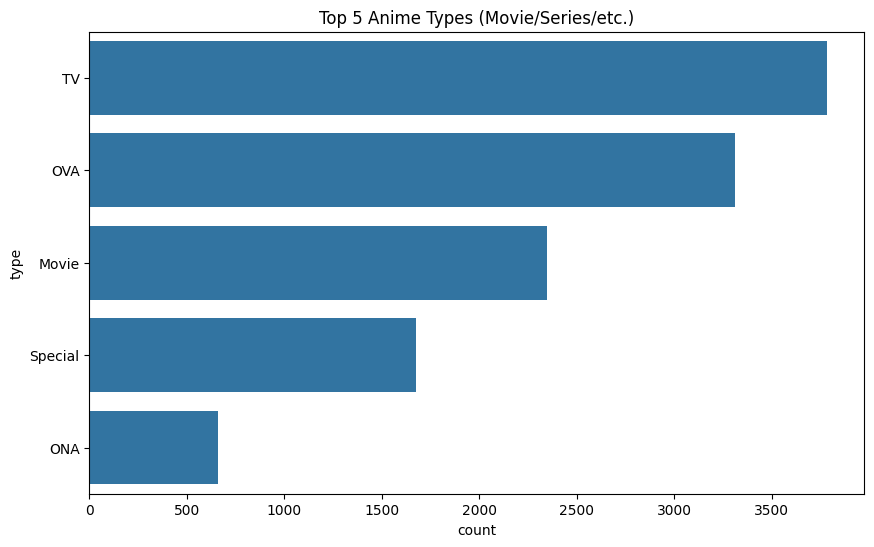

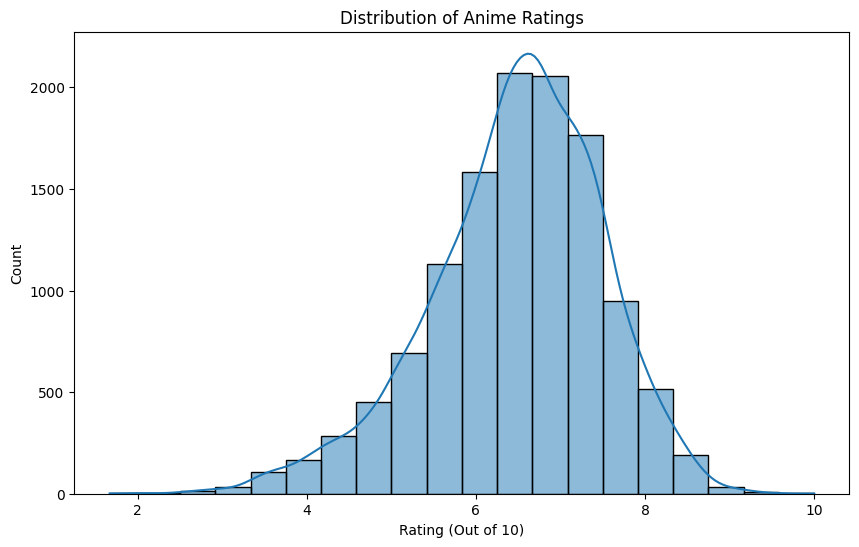

In [4]:
#Filter and visualize the dataset
print("Top 5 Highest-Rated Animes:")
display(df.sort_values("rating", ascending=False).head()[["name", "genre", "type", "rating"]])

plt.figure(figsize=(10, 6))
sns.countplot(y="type", data=df, order=df["type"].value_counts().index[:5])
plt.title("Top 5 Anime Types (Movie/Series/etc.)")
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(df["rating"], bins=20, kde=True)
plt.title("Distribution of Anime Ratings")
plt.xlabel("Rating (Out of 10)")
plt.ylabel("Count")
plt.show()

## 4. Anime Recommendation Bot
### Helper Function for Model Inference
Using Qwen 0.6B to generate personalized anime suggestions


In [5]:
def qwen_generate(prompt):
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    outputs = model.generate(
        **inputs,
        max_new_tokens=200,
        num_return_sequences=1,
        pad_token_id=tokenizer.eos_token_id , 
        temperature=0.7,
        do_sample=True
    )
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

## 5. Use Qwen 0.6B to generate personalized anime suggestions

## 5.1: Genre-Based Recommendations



In [6]:
prompt = """Suggest 3 action anime for someone who loves complex villains.  
Explain why each matches the request. Use emojis."""
response = qwen_generate(prompt)
print(response)

Suggest 3 action anime for someone who loves complex villains.  
Explain why each matches the request. Use emojis. 🎬 **Anime Suggestions for Complex Villains:**

1. **"Spirited Away" (2001)**  
   - **Why it fits:** This anime is a masterclass in complex villainy. The protagonist, Anette, is a deeply flawed, morally ambiguous character whose actions are driven by her desire for acceptance and redemption. Her villainy is nuanced, with moments of kindness and moments of cruelty, making her one of the most endearing and challenging protagonists.  
   - **Emojis:** 🎬❤️⚔️

2. **"Killer Bitch" (2013)**  
   - **Why it fits:** This anime is a gritty, morally complex tale about a woman who becomes a vigilante against a group of criminals. Her villainy is not just about violence but also about social justice and survival. The story is filled with unexpected twists and a strong, intelligent protagonist.  
   - **Emojis:** 🎬


## 5.2: Underrated Gems


In [7]:
prompt = "List 3 underrated anime with unique art styles. Include genres and summaries."
print(qwen_generate(prompt))

List 3 underrated anime with unique art styles. Include genres and summaries. Here are three underrated anime with unique art styles that are worth exploring:

1. **"Sailor Moon" (Japanese: うたびものまみ, Utabi Mamanami)**  
   - **Genre**: Action, Drama, Fantasy  
   - **Summary**: This anime is a spin-off from the iconic "Sailor Moon" manga, focusing on the adventures of Princess Aurora and her friends in a fantastical world. The art style is characterized by intricate, hand-drawn illustrations that blend traditional and digital techniques, creating a visually stunning and nostalgic experience. The anime also features a strong sense of color and contrast, enhancing the emotional impact of the story.

2. **"Demon Slayer: Kimetsu no Yaiba" (Japanese: 蛇魔の獣, Demon Slayer: Kimetsu no Yaiba)**  
   - **Genre**: Action, Drama, Adventure  
   - **Summary**: This anime is set in the world of Demon Slayer


## 5.3: Analyze Trends with Qwen


In [8]:
prompt = """The dataset shows 40% of top-rated animes are action-themed.  
Explain why action anime dominates global popularity. List 3 cultural/historical reasons."""
analysis = qwen_generate(prompt)
print(analysis)

The dataset shows 40% of top-rated animes are action-themed.  
Explain why action anime dominates global popularity. List 3 cultural/historical reasons.  
(2 marks)
Answer:
We are given a dataset showing that $40\%$ of top-rated anime are action-themed. We are asked to explain why action anime dominates global popularity and to provide three cultural/historical reasons for this dominance.

*What are the cultural and historical reasons for the dominance of action anime?* As we know, the popularity of anime can be influenced by cultural and historical factors. Some of these factors are:

1. **Cultural Influence**: In the past, anime has often been the mirror of Japanese society. Anime, especially in its early stages, was mostly focused on portraying traditional Japanese culture, customs, and values. This cultural influence has been a key reason why action anime, which often showcases modern, Western-style action and combat scenes, has gained a significant following. As a result, action a

#### *From initial Qwen3 interactions based on general knowledge, now we will using the dataset with qwen3 mode. This shift demonstrably enhanced the LLM's ability to provide targeted and insightful anime recommendations, highlighting the strength of data-augmented LLM applications.*
## **5.4: LLM + Dataset Interaction**
### 1. Filter Recommendations Using Data - Combine dataset filters with AI creativity!



In [9]:
# **Convert the 'episodes' column to numeric if it's not already**
if df['episodes'].dtype == 'object':
    df['episodes'] = pd.to_numeric(df['episodes'], errors='coerce')
    # Remove rows where conversion failed (NaN values in 'episodes')
    df.dropna(subset=['episodes'], inplace=True)

# Filter dataset for short series (<=12 episodes)
short_series = df[(df["episodes"] <= 12) & (df["episodes"] > 1)].sort_values("rating", ascending=False)

#Prompting with dataset results
prompt = f"""Based on this list of short anime:\n{short_series.head(5)[['name', 'genre', 'rating']]}\n\n
Suggest 2 binge-worthy short series and explain why they're worth watching."""
print(qwen_generate(prompt))

Based on this list of short anime:
                                                 name  \
5   Haikyuu!!: Karasuno Koukou VS Shiratorizawa Ga...   
17                      Mushishi Zoku Shou 2nd Season   
21  Rurouni Kenshin: Meiji Kenkaku Romantan - Tsui...   
23                                      One Punch Man   
27                                 Mushishi Zoku Shou   

                                                genre  rating  
5              Comedy, Drama, School, Shounen, Sports    9.15  
17  Adventure, Fantasy, Historical, Mystery, Seine...    8.88  
21  Action, Drama, Historical, Martial Arts, Roman...    8.83  
23  Action, Comedy, Parody, Sci-Fi, Seinen, Super ...    8.82  
27  Adventure, Fantasy, Historical, Mystery, Seine...    8.80  


Suggest 2 binge-worthy short series and explain why they're worth watching. Based on the provided list of short anime and their respective genres, ratings, and summaries, two binge-worthy short series that I would recommend are:

1. **M

## 5.5: Recommend Based on Mood + Dataset
#### Here, we leverage Qwen3's reasoning capabilities, evident in its self-generated "thinking" process, to understand user-stated moods. By grounding this inherent understanding with a curated list of anime titles, genres, and ratings from our dataset, we move beyond generic suggestions. This approach empowers Qwen3 to make more contextually relevant and data-backed recommendations, demonstrating the synergy between its intrinsic knowledge processing and the power of external information.


In [10]:
def recommend_anime_with_context_direct(mood, top_k=5):
    # Build prompt context from dataset
    context = "\n".join([
        f"{row['name']} ({row['genre']}): Rating {row['rating']}"
        for _, row in df.sort_values('rating', ascending=False).head(20).iterrows()
    ])

    prompt = f"""
<thinking>
Okay, the user is feeling "{mood}". I need to recommend some anime that match this emotional state.
First, I'll look at the genres typically associated with this mood — for example, melancholic moods might align with Drama or Tragedy.
Next, I'll scan the provided list of anime and check their genres and description.
I should prioritize ones with high scores and positive community feedback.
Finally, I'll summarize each recommendation clearly, explaining why it fits the mood.
</thinking>

Based on the following anime list, recommend up to {top_k} titles that best fit someone feeling "{mood}".

Anime List:
{context}

Recommendations:
"""
    result = qwen_generate(prompt)
    print("Recommendations:")
    print(result.replace('\n', '\n  ')) # Adding indentation for better readability
    return result

# Call func
#recommend_anime_with_context_direct(input("Please Enter your mood, I will recommend top anime for you"))
recommend_anime_with_context_direct('Action')


Recommendations:

  <thinking>
  Okay, the user is feeling "Action". I need to recommend some anime that match this emotional state.
  First, I'll look at the genres typically associated with this mood — for example, melancholic moods might align with Drama or Tragedy.
  Next, I'll scan the provided list of anime and check their genres and description.
  I should prioritize ones with high scores and positive community feedback.
  Finally, I'll summarize each recommendation clearly, explaining why it fits the mood.
  </thinking>
  
  Based on the following anime list, recommend up to 5 titles that best fit someone feeling "Action".
  
  Anime List:
  Taka no Tsume 8: Yoshida-kun no X-Files (Comedy, Parody): Rating 10.0
  Mogura no Motoro (Slice of Life): Rating 9.5
  Kimi no Na wa. (Drama, Romance, School, Supernatural): Rating 9.37
  Kahei no Umi (Historical): Rating 9.33
  Fullmetal Alchemist: Brotherhood (Action, Adventure, Drama, Fantasy, Magic, Military, Shounen): Rating 9.26
  Gin

'\n<thinking>\nOkay, the user is feeling "Action". I need to recommend some anime that match this emotional state.\nFirst, I\'ll look at the genres typically associated with this mood — for example, melancholic moods might align with Drama or Tragedy.\nNext, I\'ll scan the provided list of anime and check their genres and description.\nI should prioritize ones with high scores and positive community feedback.\nFinally, I\'ll summarize each recommendation clearly, explaining why it fits the mood.\n</thinking>\n\nBased on the following anime list, recommend up to 5 titles that best fit someone feeling "Action".\n\nAnime List:\nTaka no Tsume 8: Yoshida-kun no X-Files (Comedy, Parody): Rating 10.0\nMogura no Motoro (Slice of Life): Rating 9.5\nKimi no Na wa. (Drama, Romance, School, Supernatural): Rating 9.37\nKahei no Umi (Historical): Rating 9.33\nFullmetal Alchemist: Brotherhood (Action, Adventure, Drama, Fantasy, Magic, Military, Shounen): Rating 9.26\nGintama° (Action, Comedy, Histori

### From Anime Chat to Data-Informed Insights
Witness how structured anime data transforms Qwen3's understanding, moving beyond simple interaction to insightful analysis and targeted recommendations.

| **🎯 What You’re Missing If You Skip the Dataset?** | **With Dataset** | **Without Dataset** |
|-----------------------------------------------|--------------|-----------------|
| Filter by genre/rating/episode count          | ✅ Yes       | ❌ No           |
| Show actual stats (e.g., "Top 5 rated")       | ✅ Yes       | ❌ Hardcoded or generic |
| Build personalized filters                     | ✅ Yes       | ❌ Very limited   |
| Add interactivity (e.g., UI)                 | ✅ Yes       | ❌ Harder to justify results |


### What actually done in this notebook
- Qwen is the Storyteller & Recommender – creative, expressive, knows a lot.
- Dataset is the Library – full of facts, lists, numbers, and structure.

You wouldn’t ask a storyteller to guess what books are in a library — instead, show them the shelves and say:
"From these books, which would you recommend to a fantasy fan?"
That’s exactly what our notebook does!
